# 3.3 Retrieval: Finding the Right Chunks

**Applied AI Engineering · Module 3: Retrieval-Augmented Generation**

In 3.1 we chunked documents. In 3.2 we embedded the chunks and stored them in a vector database. Now we answer the question that decides whether a RAG app works at all:

> **Given a user's question, which chunks should we hand to the LLM?**

An LLM can only answer from the context we give it. If retrieval brings the wrong chunk, even the best model gives a wrong or made-up answer. *Garbage in, garbage out.*

**By the end you will be able to:**
1. Run top-k similarity search with metadata filters in Chroma
2. **Measure** retrieval quality with Hit@k, Recall@k and MRR
3. Use a similarity threshold to say "I don't know"
4. Explain and code **BM25** keyword search
5. Combine dense + keyword results with **hybrid search** (Reciprocal Rank Fusion)
6. Remove duplicate results with **MMR**
7. Improve ranking with a **cross-encoder re-ranker**
8. Fix vague questions with **query rewriting, multi-query and HyDE**
9. Build a full retrieval pipeline and a grounded prompt with citations

## 0. Setup
Uncomment and run the install line once. The first run downloads two small models (about 90 MB each).

In [1]:
# !pip install -q sentence-transformers chromadb rank_bm25 scikit-learn matplotlib pandas numpy

In [2]:
import os, re, random, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREEN, RED, GREY, PURPLE = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#9aa5b1", "#8172B3"
random.seed(1); np.random.seed(1)
print("Ready")

Ready


## 1. The retrieval step, zoomed in
A basic RAG app does one similarity search. Production RAG apps add stages around it. This notebook builds each stage one at a time:

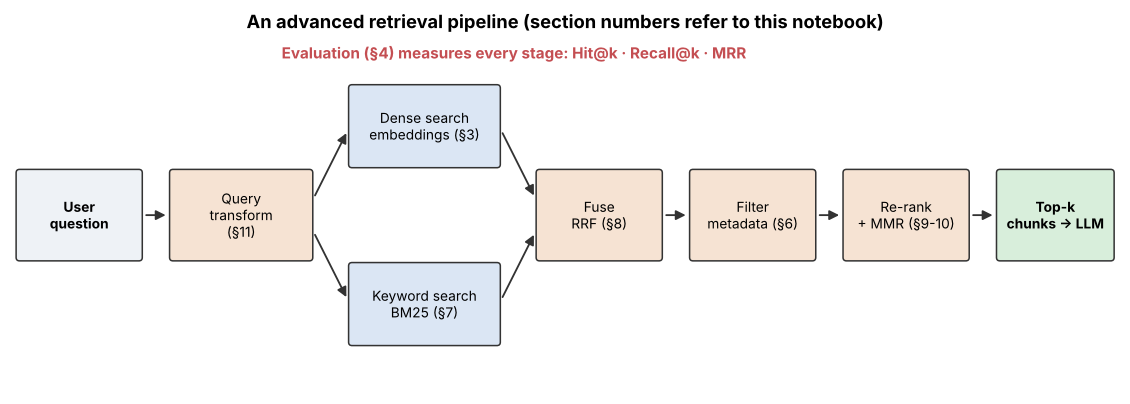

In [3]:
def box(ax, x, y, w, h, text, fc, bold=False, fs=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04", fc=fc, ec="#333", lw=1))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal")
def arrow(ax, p, q):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=13, color="#333", lw=1.2))

fig, ax = plt.subplots(figsize=(13, 4.2)); ax.set_xlim(0, 13); ax.set_ylim(0, 4.2); ax.axis("off")
box(ax, 0.1, 1.6, 1.4, 1.0, "User\nquestion", "#eef2f6", True)
box(ax, 1.9, 1.6, 1.6, 1.0, "Query\ntransform\n(§11)", "#f6e3d3")
box(ax, 4.0, 2.7, 1.7, 0.9, "Dense search\nembeddings (§3)", "#dbe6f4")
box(ax, 4.0, 0.6, 1.7, 0.9, "Keyword search\nBM25 (§7)", "#dbe6f4")
box(ax, 6.2, 1.6, 1.4, 1.0, "Fuse\nRRF (§8)", "#f6e3d3")
box(ax, 8.0, 1.6, 1.4, 1.0, "Filter\nmetadata (§6)", "#f6e3d3")
box(ax, 9.8, 1.6, 1.4, 1.0, "Re-rank\n+ MMR (§9-10)", "#f6e3d3")
box(ax, 11.6, 1.6, 1.3, 1.0, "Top-k\nchunks → LLM", "#d8eedb", True)
arrow(ax, (1.55, 2.1), (1.85, 2.1)); arrow(ax, (3.55, 2.3), (3.95, 3.1)); arrow(ax, (3.55, 1.9), (3.95, 1.1))
arrow(ax, (5.75, 3.1), (6.15, 2.3)); arrow(ax, (5.75, 1.1), (6.15, 1.9))
arrow(ax, (7.65, 2.1), (7.95, 2.1)); arrow(ax, (9.45, 2.1), (9.75, 2.1)); arrow(ax, (11.25, 2.1), (11.55, 2.1))
ax.text(5.9, 3.95, "Evaluation (§4) measures every stage: Hit@k · Recall@k · MRR", ha="center", fontsize=10, color=RED, fontweight="bold")
ax.set_title("An advanced retrieval pipeline (section numbers refer to this notebook)", fontsize=12, fontweight="bold")
plt.show()

## 2. Our knowledge base: the *Nova Retail* employee handbook
We use a small, realistic HR handbook so we can check every answer by eye. It contains some deliberate traps that real company data always has:
- **Old versions** of policies (`L1-old`, `R1-old` from 2024) that disagree with the 2025 versions
- **Near-duplicates** of the work-from-home rule from the handbook, an FAQ and a Slack message
- **Exact codes and acronyms** (VPN-417, LTA, POSH) that embeddings can struggle with

Each chunk is: `(id, section, year, source, text)`.

In [4]:
KB = [
    ('L1', 'Leave', 2025, 'handbook', 'Full-time employees receive 24 days of paid annual leave per calendar year.'),
    ('L1-old', 'Leave', 2024, 'handbook', 'Full-time employees receive 20 days of paid annual leave per calendar year.'),
    ('L2', 'Leave', 2025, 'handbook', 'Up to 10 unused annual leave days can be carried forward to the next year.'),
    ('L3', 'Leave', 2025, 'handbook', 'Sick leave is 8 days per year. A medical certificate is needed for absences longer than 2 days.'),
    ('L4', 'Leave', 2025, 'handbook', 'Maternity leave is 26 weeks of paid leave and paternity leave is 2 weeks.'),
    ('T1', 'Travel', 2025, 'handbook', 'Economy class is used for all flights shorter than 6 hours.'),
    ('T2', 'Travel', 2025, 'handbook', 'Business class is allowed only for international flights longer than 6 hours, with director approval.'),
    ('T3', 'Travel', 2025, 'handbook', 'Hotel bookings must be made through the company travel desk at least 3 days in advance.'),
    ('T4', 'Travel', 2025, 'handbook', 'The daily meal allowance during business travel is Rs 1,500 in metro cities.'),
    ('R1', 'Expenses', 2025, 'handbook', 'Expense claims must be submitted within 30 days along with original receipts.'),
    ('R1-old', 'Expenses', 2024, 'handbook', 'Expense claims must be submitted within 60 days along with original receipts.'),
    ('R2', 'Expenses', 2025, 'handbook', 'Approved reimbursement claims are paid with the next monthly salary.'),
    ('I1', 'IT', 2025, 'handbook', 'Passwords must be changed every 90 days and contain at least 12 characters.'),
    ('I2', 'IT', 2025, 'handbook', 'Laptops must be locked whenever they are left unattended.'),
    ('I3', 'IT', 2025, 'handbook', 'Error code VPN-417 means your VPN certificate has expired; raise a ticket with IT to renew it.'),
    ('I4', 'IT', 2025, 'handbook', 'Error code VPN-418 means the VPN server is under maintenance; try again after 30 minutes.'),
    ('I6', 'IT', 2025, 'handbook', 'Error code VPN-410 means the password you entered is wrong; reset it on the IT portal.'),
    ('I7', 'IT', 2025, 'handbook', 'Error code VPN-412 means your device is not registered; register it with the IT helpdesk.'),
    ('I8', 'IT', 2025, 'handbook', 'Error code VPN-415 means too many devices are connected; disconnect one device and retry.'),
    ('I5', 'IT', 2025, 'handbook', 'Two-factor authentication is mandatory for email and the HR portal.'),
    ('W1', 'Remote work', 2025, 'handbook', 'Employees may work from home up to two days per week with manager approval.'),
    ('W1-faq', 'Remote work', 2025, 'faq', "Working from home is permitted for a maximum of two days each week, subject to your manager's approval."),
    ('W1-chat', 'Remote work', 2025, 'slack', 'WFH: 2 days a week is allowed if your manager agrees.'),
    ('W2', 'Remote work', 2025, 'handbook', 'Working remotely from another country requires HR and legal approval in advance.'),
    ('W3', 'Remote work', 2025, 'handbook', 'Remote employees receive a one-time home office allowance of Rs 10,000 for a chair and desk.'),
    ('P1', 'Performance', 2025, 'handbook', 'Performance reviews take place twice a year, in June and December.'),
    ('P2', 'Performance', 2025, 'handbook', "Employees rated 'exceeds expectations' are eligible for a bonus of up to 15% of annual salary."),
    ('B4', 'Benefits', 2025, 'handbook', 'LTA can be claimed twice in a block of four years by submitting travel tickets to payroll.'),
    ('H1', 'Conduct', 2025, 'handbook', 'Complaints under the POSH policy are handled by the Internal Committee; email ic@novaretail.in.'),
    ('H2', 'Conduct', 2025, 'handbook', 'Gifts from vendors worth more than Rs 2,000 must be declared to the compliance team.'),
    ('B1', 'Benefits', 2025, 'handbook', 'Health insurance covers the employee, spouse, two children and parents up to Rs 5 lakh per year.'),
    ('B2', 'Benefits', 2025, 'handbook', 'Employees get a 20% discount on all Nova Retail products in stores and online.'),
    ('B3', 'Benefits', 2025, 'handbook', 'The company gym on the 3rd floor is free for employees and open from 6 am to 10 pm.'),
]

df = pd.DataFrame(KB, columns=['id', 'section', 'year', 'source', 'text'])
print(len(df), 'chunks')
df.head(8)

33 chunks


,id,section,year,source,text
0,L1,Leave,2025,handbook,Full-time employees receive 24 days of paid an...
1,L1-old,Leave,2024,handbook,Full-time employees receive 20 days of paid an...
2,L2,Leave,2025,handbook,Up to 10 unused annual leave days can be carri...
3,L3,Leave,2025,handbook,Sick leave is 8 days per year. A medical certi...
4,L4,Leave,2025,handbook,Maternity leave is 26 weeks of paid leave and ...
5,T1,Travel,2025,handbook,Economy class is used for all flights shorter ...
6,T2,Travel,2025,handbook,Business class is allowed only for internation...
7,T3,Travel,2025,handbook,Hotel bookings must be made through the compan...


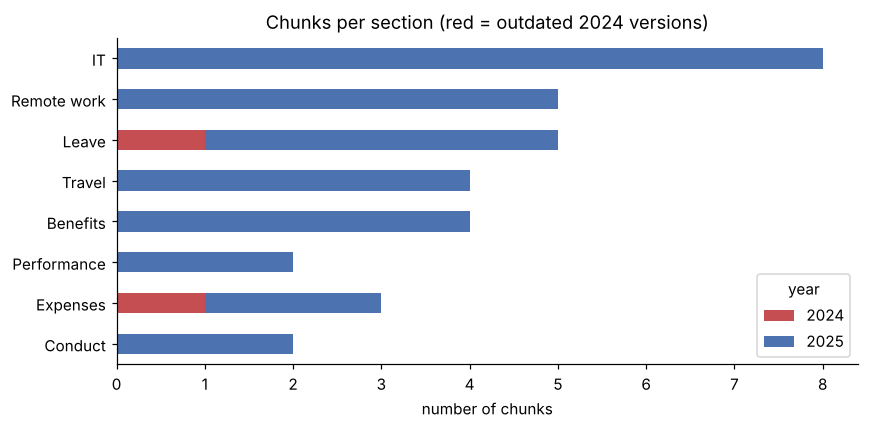

In [5]:
counts = df.groupby(["section", "year"]).size().unstack(fill_value=0).sort_values(2025)
ax = counts.plot.barh(stacked=True, color=[RED, BLUE], figsize=(8, 4))
ax.set_xlabel("number of chunks"); ax.set_ylabel("")
ax.set_title("Chunks per section (red = outdated 2024 versions)"); ax.legend(title="year")
plt.tight_layout(); plt.show()

### Test questions with known answers
To *measure* retrieval we need questions where we already know which chunk is correct (a "golden set"). In a real project you would write 30–100 of these with the people who own the documents.

In [6]:
TESTS = [
    ('How many vacation days do I get each year?', ['L1']),
    ('Can I save unused holidays for next year?', ['L2']),
    ('What does VPN-417 mean?', ['I3']),
    ('My laptop shows VPN-418, what should I do?', ['I4']),
    ('Can I fly business class to London?', ['T2']),
    ('How long do I have to submit my expenses?', ['R1']),
    ('When will I get my money back for a claim?', ['R2']),
    ('What does error VPN-412 mean?', ['I7']),
    ('Got VPN-415 on my phone, how to fix?', ['I8']),
    ('How often should I change my password?', ['I1']),
    ('What are the rules for working remotely?', ['W1', 'W1-faq', 'W1-chat', 'W2', 'W3']),
    ('Does the insurance cover my parents?', ['B1']),
    ('When is my appraisal?', ['P1']),
    ('Is there a bonus for top performers?', ['P2']),
    ('How much can I spend on food when travelling?', ['T4']),
    ("Do I need a doctor's note when I'm sick?", ['L3']),
    ('How many weeks off do new mothers get?', ['L4']),
    ('Is there a staff discount?', ['B2']),
    ('How often can I claim LTA?', ['B4']),
    ('Where do I report a POSH issue?', ['H1']),
]
print(f'{len(TESTS)} test questions')

20 test questions


## 3. Baseline: dense top-k similarity search
This is exactly what we built in 3.2: embed the question and return the *k* chunks with the highest cosine similarity. We store the chunks in **Chroma** with their metadata.

In [7]:
import chromadb
from chromadb.utils import embedding_functions
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")
ef = embedding_functions.SentenceTransformerEmbeddingFunction(model_name="all-MiniLM-L6-v2")
client = chromadb.Client()
try: client.delete_collection("handbook")
except Exception: pass
col = client.create_collection("handbook", embedding_function=ef, metadata={"hnsw:space": "cosine"})
col.add(ids=df.id.tolist(), documents=df.text.tolist(),
        metadatas=df[["section", "year", "source"]].to_dict("records"))

IDS, TEXTS = df.id.tolist(), df.text.tolist()
TEXT = dict(zip(IDS, TEXTS))

def dense_search(query, k=5, where=None):
    """Return [(chunk_id, cosine_similarity), ...] best first."""
    r = col.query(query_texts=[query], n_results=min(k, col.count()), where=where)
    return [(i, 1 - d) for i, d in zip(r["ids"][0], r["distances"][0])]

for cid, s in dense_search("How many vacation days do I get each year?", k=4):
    print(f"{s:.3f}  {cid:8s} {TEXT[cid]}")

0.554  L2       Up to 10 unused annual leave days can be carried forward to the next year.
0.539  L1       Full-time employees receive 24 days of paid annual leave per calendar year.
0.532  L1-old   Full-time employees receive 20 days of paid annual leave per calendar year.
0.406  W1-chat  WFH: 2 days a week is allowed if your manager agrees.


**Problem spotted already:** the question is about annual leave, but the 2024 version (`L1-old`, *20 days*) is in the top results next to the 2025 version (*24 days*). If both go to the LLM, it might answer 20. We fix this in §6.

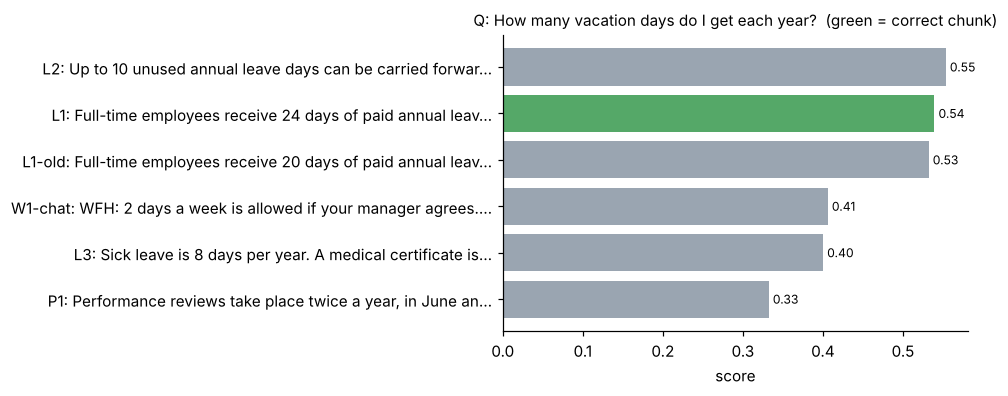

In [8]:
def plot_results(query, results, relevant=(), title=None, ax=None):
    show = ax is None
    if ax is None: fig, ax = plt.subplots(figsize=(9, 0.45 * len(results) + 1))
    labels = [f"{cid}: {TEXT[cid][:55]}…" for cid, _ in results][::-1]
    scores = [s for _, s in results][::-1]
    colors = [GREEN if cid in relevant else GREY for cid, _ in results][::-1]
    ax.barh(labels, scores, color=colors)
    for y, s in enumerate(scores): ax.text(s + 0.005, y, f"{s:.2f}", va="center", fontsize=8)
    ax.set_xlabel("score"); ax.set_title(title or f"Q: {query}  (green = correct chunk)", fontsize=10)
    if show: plt.tight_layout(); plt.show()

plot_results("How many vacation days do I get each year?",
             dense_search("How many vacation days do I get each year?", k=6), relevant={"L1"})

## 4. How do we know retrieval is good? Evaluation metrics
Never judge retrieval by trying two questions. Run the whole golden set and compute metrics:

| Metric | Question it answers | Formula |
|---|---|---|
| **Hit@k** | Did *at least one* correct chunk appear in the top k? | 1 if yes, else 0 (averaged over questions) |
| **Recall@k** | What *fraction* of all correct chunks appeared in the top k? | correct found in top k ÷ total correct |
| **Precision@k** | What fraction of the top k is correct? | correct found in top k ÷ k |
| **MRR** (Mean Reciprocal Rank) | How *high* is the first correct chunk? | average of 1 ÷ rank of first correct chunk |

**MRR example:** the correct chunk is ranked 1st → 1.0; 2nd → 0.5; 3rd → 0.33; not found → 0. A high MRR means the right chunk is near the top, which matters because LLMs pay most attention to the first chunks.

In [9]:
def first_rank(ranked_ids, relevant):
    for pos, cid in enumerate(ranked_ids, 1):
        if cid in relevant: return pos
    return None

def evaluate(search_fn, ks=(1, 3, 5), tests=TESTS):
    """search_fn(query) -> ranked list of chunk ids. Returns a dict of metrics."""
    out = {f"Hit@{k}": [] for k in ks} | {f"Recall@{k}": [] for k in ks} | {"MRR": []}
    for q, rel in tests:
        ranked = search_fn(q)
        for k in ks:
            found = len(set(ranked[:k]) & set(rel))
            out[f"Hit@{k}"].append(found > 0)
            out[f"Recall@{k}"].append(found / len(rel))
        r = first_rank(ranked, rel)
        out["MRR"].append(1 / r if r else 0.0)
    return {m: round(float(np.mean(v)), 3) for m, v in out.items()}

dense_ids = lambda q, k=10, where=None: [cid for cid, _ in dense_search(q, k, where)]
baseline = evaluate(dense_ids)
pd.Series(baseline, name="Dense (baseline)").to_frame().T

,Hit@1,Hit@3,Hit@5,Recall@1,Recall@3,Recall@5,MRR
Dense (baseline),0.85,1.0,1.0,0.81,0.98,1.0,0.908


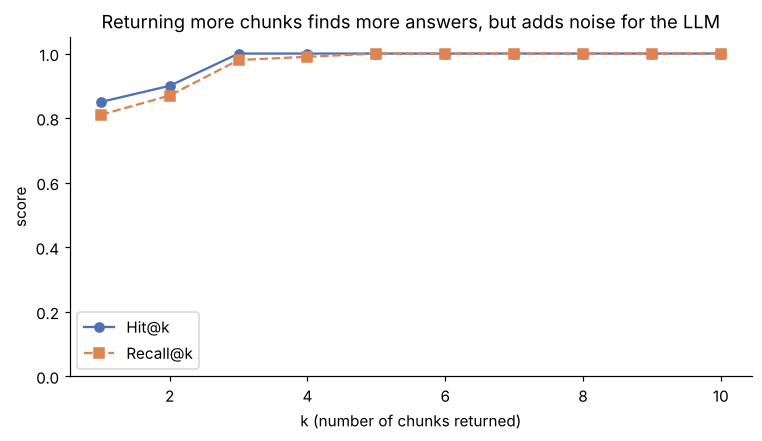

In [10]:
ks = range(1, 11)
hit = [evaluate(dense_ids, ks=(k,))[f"Hit@{k}"] for k in ks]
rec = [evaluate(dense_ids, ks=(k,))[f"Recall@{k}"] for k in ks]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ks, hit, "o-", color=BLUE, label="Hit@k"); ax.plot(ks, rec, "s--", color=ORANGE, label="Recall@k")
ax.set_xlabel("k (number of chunks returned)"); ax.set_ylabel("score"); ax.set_ylim(0, 1.05)
ax.set_title("Returning more chunks finds more answers, but adds noise for the LLM"); ax.legend()
plt.show()

**Choosing k:** a bigger k raises recall but also sends more irrelevant text to the LLM (more cost, more confusion). Typical values are **k = 3 to 5** for final context, or **retrieve 20, re-rank, keep 3–5** (see §10).

Where exactly does the correct chunk land for each question?

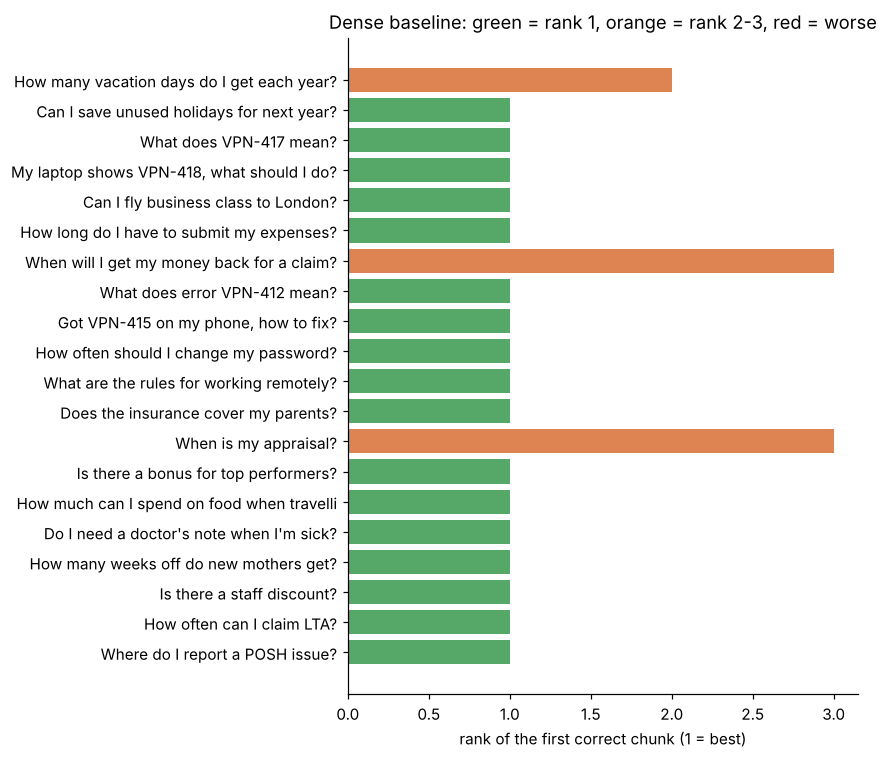

In [11]:
def rank_table(search_fn, name):
    return pd.Series({q[:42]: (first_rank(search_fn(q), rel) or 99) for q, rel in TESTS}, name=name)

ranks = rank_table(dense_ids, "Dense")
fig, ax = plt.subplots(figsize=(8, 7))
colors = [GREEN if r == 1 else (ORANGE if r <= 3 else RED) for r in ranks]
ax.barh(ranks.index[::-1], ranks.values[::-1], color=colors[::-1])
ax.set_xlabel("rank of the first correct chunk (1 = best)")
ax.set_title("Dense baseline: green = rank 1, orange = rank 2-3, red = worse")
plt.tight_layout(); plt.show()

## 5. Similarity thresholds: knowing when to say "I don't know"
Top-k search **always** returns k chunks, even for a question the handbook cannot answer. If we pass those to the LLM, it may invent an answer. A simple guard: if the best similarity is below a threshold, answer *"I couldn't find this in the handbook."*

Let's compare the top-1 score for answerable questions with questions that are **not** in the handbook.

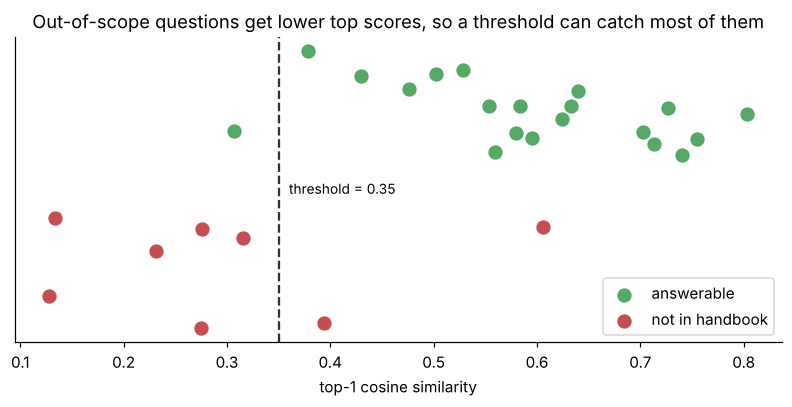

Answerable questions wrongly blocked: 1 of 20
Out-of-scope questions let through   : ['What is the share price of Nova Retail?', 'How do I book a meeting room?']

NO_MATCH → reply: 'I couldn't find this in the handbook.'
[('B1', 0.5022016763687134)]


In [12]:
OUT_OF_SCOPE = ["What is on the canteen menu today?", "Who won the cricket world cup?",
                "How do I apply for a home loan?", "What is the CEO's phone number?",
                "Can I bring my dog to the office?", "What is the share price of Nova Retail?",
                "How do I book a meeting room?", "Is the office closed for Diwali?"]
in_scores  = [dense_search(q, 1)[0][1] for q, _ in TESTS]
out_scores = [dense_search(q, 1)[0][1] for q in OUT_OF_SCOPE]

THRESHOLD = 0.35
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.scatter(in_scores, np.random.uniform(0.6, 1.0, len(in_scores)), s=70, color=GREEN, label="answerable")
ax.scatter(out_scores, np.random.uniform(0.0, 0.4, len(out_scores)), s=70, color=RED, label="not in handbook")
ax.axvline(THRESHOLD, color="#333", ls="--"); ax.text(THRESHOLD + 0.01, 0.47, f"threshold = {THRESHOLD}", fontsize=9)
ax.set_yticks([]); ax.set_xlabel("top-1 cosine similarity"); ax.legend(loc="lower right")
ax.set_title("Out-of-scope questions get lower top scores, so a threshold can catch most of them")
plt.show()

def safe_search(q, k=3, threshold=THRESHOLD):
    res = [(c, s) for c, s in dense_search(q, k) if s >= threshold]
    return res or "NO_MATCH → reply: 'I couldn't find this in the handbook.'"

print("Answerable questions wrongly blocked:", sum(s < THRESHOLD for s in in_scores), "of", len(in_scores))
print("Out-of-scope questions let through   :", [q for q, s in zip(OUT_OF_SCOPE, out_scores) if s >= THRESHOLD])
print()
print(safe_search("Can I bring my dog to the office?"))
print(safe_search("Does the insurance cover my parents?"))

**Caution:** the green and red groups overlap a little, so no threshold is perfect: a couple of out-of-scope questions still score high because they share words with real policies, and the LLM prompt must still say *"answer only from the context"* as a second guard. Pick it from data like this chart (for your model, your documents), not from a guess. Different embedding models have very different score ranges.

## 6. Metadata filtering
Metadata (from 3.2) lets us restrict the search **before** ranking: only 2025 policies, only one section, only one source file. This is the cheapest and most reliable fix for the "old version" problem.

Chroma filter operators: `$eq, $ne, $gt, $gte, $lt, $lte, $in, $nin`, combined with `$and` / `$or`.

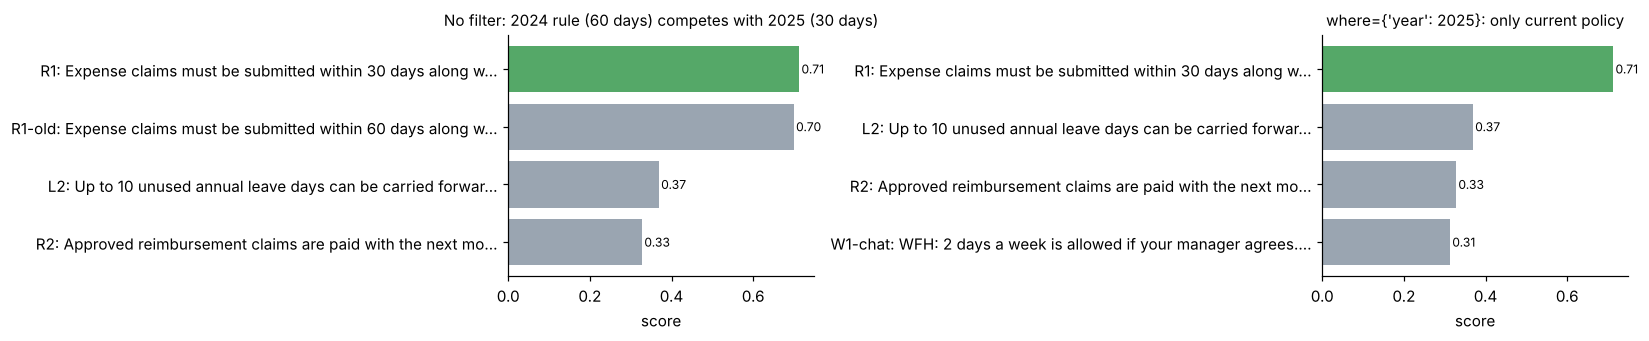

0.30 I6   Error code VPN-410 means the password you entered is wrong; reset it on the IT portal.
0.27 I1   Passwords must be changed every 90 days and contain at least 12 characters.
0.24 I3   Error code VPN-417 means your VPN certificate has expired; raise a ticket with IT to renew it.


In [13]:
q = "How long do I have to submit my expenses?"
fig, axes = plt.subplots(1, 2, figsize=(15, 3.2))
plot_results(q, dense_search(q, 4), {"R1"}, "No filter: 2024 rule (60 days) competes with 2025 (30 days)", axes[0])
plot_results(q, dense_search(q, 4, where={"year": 2025}), {"R1"}, "where={'year': 2025}: only current policy", axes[1])
plt.tight_layout(); plt.show()

# Combined filter: current IT policies only
for cid, s in dense_search("Something is wrong with my login", 3, where={"$and": [{"year": 2025}, {"section": "IT"}]}):
    print(f"{s:.2f} {cid:4s} {TEXT[cid]}")

In [14]:
dense_2025 = lambda q: dense_ids(q, 10, where={"year": 2025})
results = {"Dense": baseline, "Dense + year filter": evaluate(dense_2025)}
pd.DataFrame(results).T

,Hit@1,Hit@3,Hit@5,Recall@1,Recall@3,Recall@5,MRR
Dense,0.85,1.0,1.0,0.81,0.98,1.0,0.908
Dense + year filter,0.85,1.0,1.0,0.81,0.98,1.0,0.925


**Where does metadata come from?** You add it during ingestion (3.1): file name, page number, section heading, date, department, access level. You can also filter **by user**: an intern's search should never return chunks from salary documents marked `access: "HR-only"`.

## 7. Keyword search with BM25
Dense search understands meaning, but it can blur **exact tokens**: error codes, product IDs, names, acronyms. Classic keyword search scores a chunk by the query words it contains. **BM25** (Best Matching 25) is the standard formula, used by Elasticsearch and OpenSearch.

```
score(D, Q) = Σ over query words q:   IDF(q) × tf(q, D) × (k1 + 1)
                                       ─────────────────────────────────────────────
                                       tf(q, D) + k1 × (1 − b + b × |D| / avg_len)
```
- **tf**: how many times the word appears in the chunk (more is better, but with diminishing returns controlled by `k1`, usually 1.2–2.0)
- **IDF** (inverse document frequency): rare words count much more than common ones. `VPN-417` appears in 1 chunk, `leave` in many
- **length normalisation** (`b`, usually 0.75): a short chunk with the word beats a long chunk with the word once

In [15]:
from rank_bm25 import BM25Okapi

STOP = set("""a an the is are was do does did i my me you your to of for in on at and or what how when
can will be with it this that there get got should have has""".split())
def tokenize(s):
    # keep codes like 'vpn-417' together; drop common stop words
    return [w for w in re.findall(r"[a-z0-9]+(?:-[0-9]+)?", s.lower()) if w not in STOP]

bm25 = BM25Okapi([tokenize(t) for t in TEXTS])
print(tokenize("What does error VPN-412 mean?"))

def bm25_search(query, k=10, ids=IDS, index=None):
    index = index or bm25
    s = index.get_scores(tokenize(query))
    order = [i for i in np.argsort(-s) if s[i] > 0][:k]      # ignore chunks with zero overlap
    return [(ids[i], float(s[i])) for i in order]

for cid, s in bm25_search("What does error VPN-412 mean?", 3):
    print(f"{s:5.2f}  {cid:4s} {TEXT[cid]}")

['error', 'vpn-412', 'mean']
 5.07  I7   Error code VPN-412 means your device is not registered; register it with the IT helpdesk.
 1.77  I6   Error code VPN-410 means the password you entered is wrong; reset it on the IT portal.
 1.69  I3   Error code VPN-417 means your VPN certificate has expired; raise a ticket with IT to renew it.


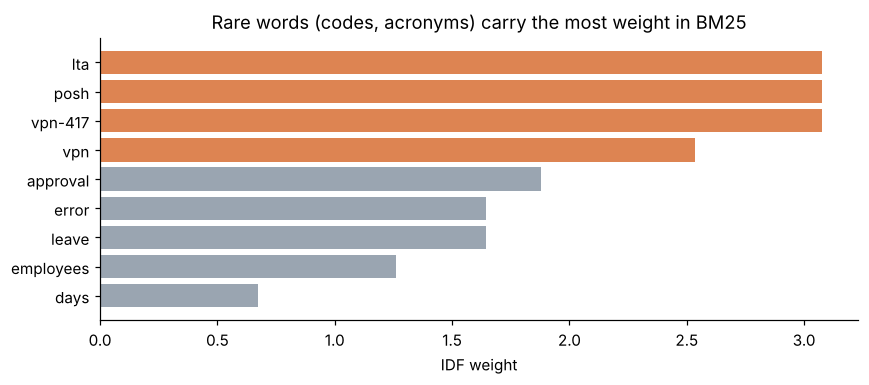

In [16]:
words = ["leave", "days", "vpn", "error", "employees", "vpn-417", "posh", "lta", "approval"]
idf = {w: bm25.idf.get(w, 0) for w in words}
idf = dict(sorted(idf.items(), key=lambda x: x[1]))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(list(idf), list(idf.values()), color=[ORANGE if v > 2 else GREY for v in idf.values()])
ax.set_xlabel("IDF weight"); ax.set_title("Rare words (codes, acronyms) carry the most weight in BM25")
plt.tight_layout(); plt.show()

### Dense vs BM25 on exact codes at scale
On our small handbook, dense search handles codes fine. Real systems contain **hundreds of similar codes**. Let's build an error-code manual with 300 entries like `Error 4821: the printer is offline.` and ask about specific codes.

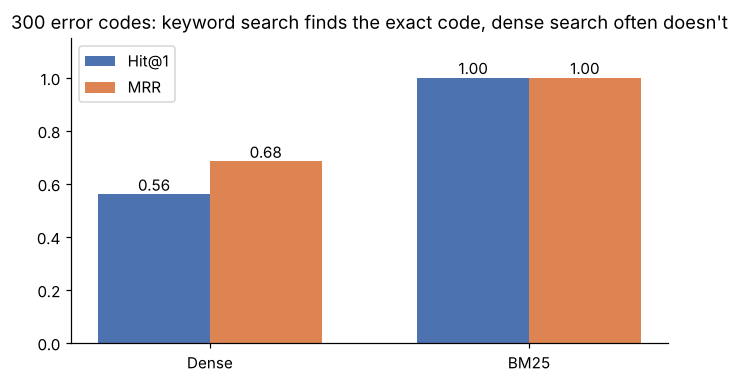

Example dense miss: What does error 9417 mean? → dense top-3: ['E9724', 'E9295', 'E9417']


In [17]:
issues = ["the printer is offline", "the badge reader rejected your card", "your mailbox is full",
          "the payroll file failed to upload", "the shared drive quota is exceeded", "your licence key has expired",
          "the POS terminal lost network", "the barcode scanner is not paired", "the stock sync job timed out",
          "the invoice PDF could not be generated"]
random.seed(1)
codes = random.sample(range(1000, 9999), 300)
code_docs = [f"Error {c}: {random.choice(issues)}." for c in codes]
code_ids = [f"E{c}" for c in codes]
code_emb = model.encode(code_docs, normalize_embeddings=True)
code_bm25 = BM25Okapi([tokenize(d) for d in code_docs])
code_tests = [(f"What does error {codes[i]} mean?", [code_ids[i]]) for i in random.sample(range(300), 50)]

def code_dense(q, k=10):
    s = code_emb @ model.encode([q], normalize_embeddings=True)[0]
    return [code_ids[i] for i in np.argsort(-s)[:k]]
def code_sparse(q, k=10):
    return [cid for cid, _ in bm25_search(q, k, ids=code_ids, index=code_bm25)]

code_scores = {"Dense": evaluate(code_dense, tests=code_tests), "BM25": evaluate(code_sparse, tests=code_tests)}
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(2); w = 0.35
for j, (m, c) in enumerate([("Hit@1", BLUE), ("MRR", ORANGE)]):
    bars = ax.bar(x + j * w, [code_scores[n][m] for n in code_scores], w, color=c, label=m)
    ax.bar_label(bars, fmt="%.2f")
ax.set_xticks(x + w / 2); ax.set_xticklabels(code_scores); ax.set_ylim(0, 1.15)
ax.set_title("300 error codes: keyword search finds the exact code, dense search often doesn't"); ax.legend()
plt.show()
print("Example dense miss:", code_tests[0][0], "→ dense top-3:", code_dense(code_tests[0][0], 3))

**Why does dense fail here?** To an embedding model, "Error 4821" and "Error 4812" look almost identical: same shape, same topic. BM25 treats `4821` as a rare exact word and matches it perfectly. But BM25 fails when the user paraphrases ("vacation" vs "annual leave"). **We want both.**

In [18]:
both = {"Dense": baseline, "BM25": evaluate(lambda q: [c for c, _ in bm25_search(q)])}
pd.DataFrame(both).T

,Hit@1,Hit@3,Hit@5,Recall@1,Recall@3,Recall@5,MRR
Dense,0.85,1.0,1.0,0.81,0.98,1.00,0.908
BM25,0.65,0.7,0.7,0.61,0.67,0.67,0.683


## 8. Hybrid search with Reciprocal Rank Fusion (RRF)
Dense scores (cosine, 0–1) and BM25 scores (0 to ~15) are on different scales, so we can't simply add them. **RRF** ignores the scores and uses only the **ranks**:

```
RRF_score(chunk) = Σ over each result list:  1 / (k + rank of chunk in that list)        k = 60 by convention
```
A chunk ranked high by **either** method gets a good score; a chunk ranked high by **both** gets the best score.

**Worked example (k = 60):**

| Chunk | Dense rank | BM25 rank | RRF score |
|---|---|---|---|
| A | 1 | 3 | 1/61 + 1/63 = 0.0323 |
| B | 2 | — | 1/62 = 0.0161 |
| C | 5 | 1 | 1/65 + 1/61 = 0.0318 |

A wins (good in both), C is close (top in BM25), B drops (only one list liked it).

In [19]:
def rrf(*ranked_lists, k=60, weights=None):
    weights = weights or [1] * len(ranked_lists)
    scores = {}
    for lst, w in zip(ranked_lists, weights):
        for rank, cid in enumerate(lst, 1):
            scores[cid] = scores.get(cid, 0) + w / (k + rank)
    return sorted(scores, key=scores.get, reverse=True)

YEAR = dict(zip(df.id, df.year))

def hybrid_ids(q, k=10, year=None):
    # Dense + BM25 fused with RRF; optional year filter applied to both lists
    d = dense_ids(q, 20, where={"year": year} if year else None)
    s = [c for c, _ in bm25_search(q, 20) if year is None or YEAR[c] == year]
    return rrf(d, s)[:k]

print(hybrid_ids("What does VPN-417 mean?", 3))

['I3', 'I6', 'I7']


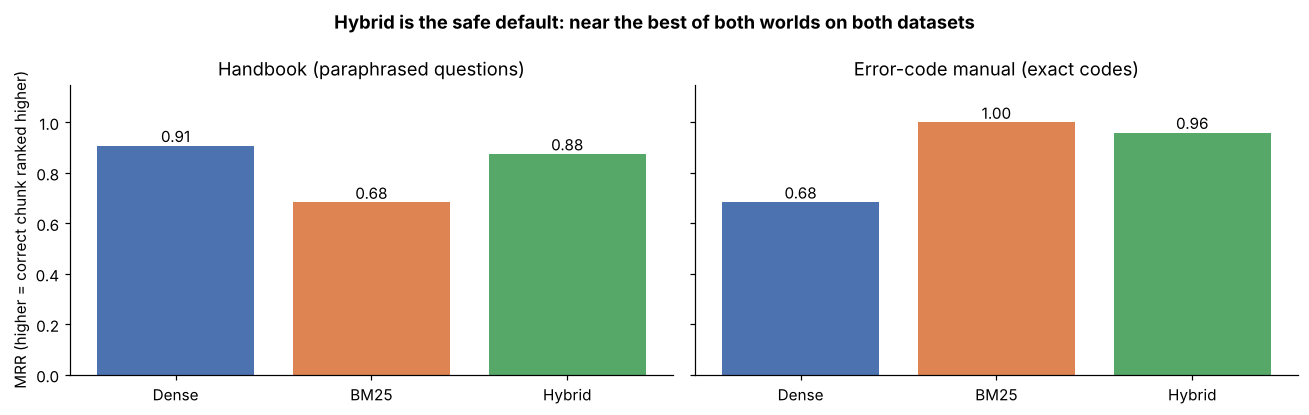

In [20]:
code_hybrid = lambda q: rrf(code_dense(q, 20), code_sparse(q, 20))
handbook = {"Dense": baseline, "BM25": both["BM25"], "Hybrid": evaluate(hybrid_ids)}
codesets = {"Dense": code_scores["Dense"], "BM25": code_scores["BM25"], "Hybrid": evaluate(code_hybrid, tests=code_tests)}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (title, res) in zip(axes, [("Handbook (paraphrased questions)", handbook), ("Error-code manual (exact codes)", codesets)]):
    bars = ax.bar(list(res), [res[n]["MRR"] for n in res], color=[BLUE, ORANGE, GREEN])
    ax.bar_label(bars, fmt="%.2f"); ax.set_title(title); ax.set_ylim(0, 1.15)
axes[0].set_ylabel("MRR (higher = correct chunk ranked higher)")
fig.suptitle("Hybrid is the safe default: near the best of both worlds on both datasets", fontweight="bold")
plt.tight_layout(); plt.show()

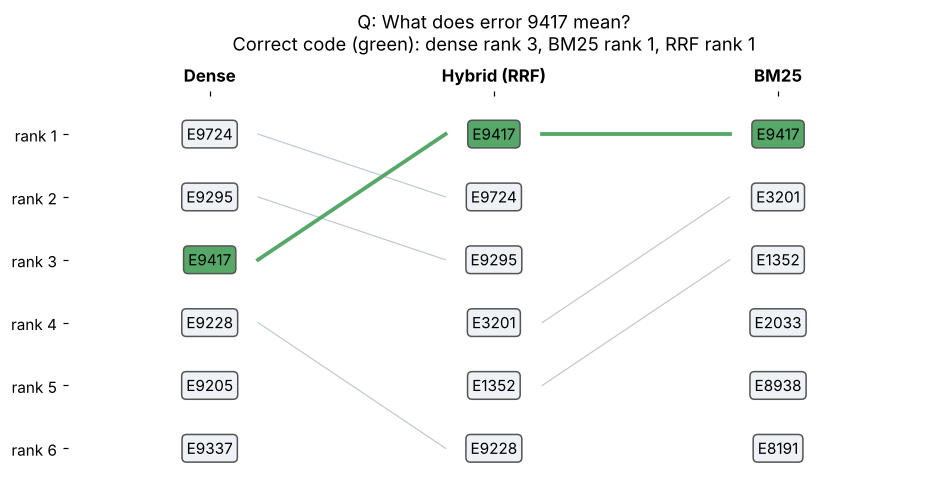

In [21]:
# Visualise RRF on one error-code question where dense search gets it wrong
q, rel = code_tests[0]
d, s_, h = code_dense(q, 6), code_sparse(q, 6), rrf(code_dense(q, 20), code_sparse(q, 20))[:6]
cols = {"Dense": (0, d), "Hybrid (RRF)": (1, h), "BM25": (2, s_)}
fig, ax = plt.subplots(figsize=(10, 4.6))
for name, (x, lst) in cols.items():
    for r, cid in enumerate(lst):
        ax.text(x, -r, cid, ha="center", va="center", fontsize=10,
                bbox=dict(boxstyle="round", fc=GREEN if cid in rel else "#eef2f6", ec="#555"))
for name in ["Dense", "BM25"]:
    x, lst = cols[name]
    for cid in lst:
        if cid in h:
            ok = cid in rel
            ax.plot([x + (0.17 if x == 0 else -0.17), 1 + (-0.17 if x == 0 else 0.17)], [-lst.index(cid), -h.index(cid)],
                    color=GREEN if ok else GREY, lw=2.5 if ok else 0.8, alpha=1 if ok else 0.6, zorder=0)
ax.set_xticks(range(3)); ax.set_xticklabels(cols, fontsize=11, fontweight="bold"); ax.xaxis.tick_top()
ax.set_yticks([-r for r in range(6)]); ax.set_yticklabels([f"rank {r + 1}" for r in range(6)])
ax.set_xlim(-0.5, 2.5); ax.set_ylim(-5.6, 0.6); ax.spines[:].set_visible(False)
pos = lambda lst: lst.index(rel[0]) + 1 if rel[0] in lst else "outside top 6"
ax.set_title(f"Q: {q}\nCorrect code (green): dense rank {pos(d)}, BM25 rank {pos(s_)}, RRF rank {pos(h)}", pad=30)
plt.show()

**Takeaway:** dense wins on paraphrases, BM25 wins on exact codes, and hybrid is close to the winner on *both*. Since you rarely know in advance what users will type, hybrid is the common production default. You can also tune `weights=[0.7, 0.3]` in `rrf()` to favour one side.

## 9. MMR: Maximal Marginal Relevance (removing duplicates)
Ask *"Can I work from home?"* and plain top-k returns the same WFH rule twice (handbook and FAQ, and the Slack copy is close behind). That wastes the LLM's context and pushes out other relevant rules (working abroad, home office allowance).

**MMR** picks results one at a time, balancing *relevance to the question* against *similarity to what's already picked*:

```
MMR = argmax over remaining chunks d:   λ · sim(d, query)  −  (1 − λ) · max sim(d, already selected)
```
- **λ = 1** → pure relevance (same as normal top-k)
- **λ = 0** → pure diversity
- typical **λ = 0.5 to 0.7**

In [22]:
EMB = dict(zip(IDS, model.encode(TEXTS, normalize_embeddings=True)))

def mmr(query, candidates, k=4, lam=0.5):
    qv = model.encode([query], normalize_embeddings=True)[0]
    rel = {c: float(EMB[c] @ qv) for c in candidates}
    selected = []
    while len(selected) < min(k, len(candidates)):
        def score(c):
            redundancy = max((float(EMB[c] @ EMB[s]) for s in selected), default=0)
            return lam * rel[c] - (1 - lam) * redundancy
        best = max((c for c in candidates if c not in selected), key=score)
        selected.append(best)
    return selected

q = "Can I work from home?"
cands = dense_ids(q, 12, where={"year": 2025})
plain, diverse = cands[:3], mmr(q, cands, k=3, lam=0.7)
for name, lst in [("Plain top-3", plain), ("MMR top-3 (λ=0.7)", diverse)]:
    print(f"\n{name}:"); [print(f"   {c:8s} {TEXT[c]}") for c in lst]


Plain top-3:
   W1-faq   Working from home is permitted for a maximum of two days each week, subject to your manager's approval.
   W1       Employees may work from home up to two days per week with manager approval.
   W2       Working remotely from another country requires HR and legal approval in advance.

MMR top-3 (λ=0.7):
   W1-faq   Working from home is permitted for a maximum of two days each week, subject to your manager's approval.
   W2       Working remotely from another country requires HR and legal approval in advance.
   W3       Remote employees receive a one-time home office allowance of Rs 10,000 for a chair and desk.


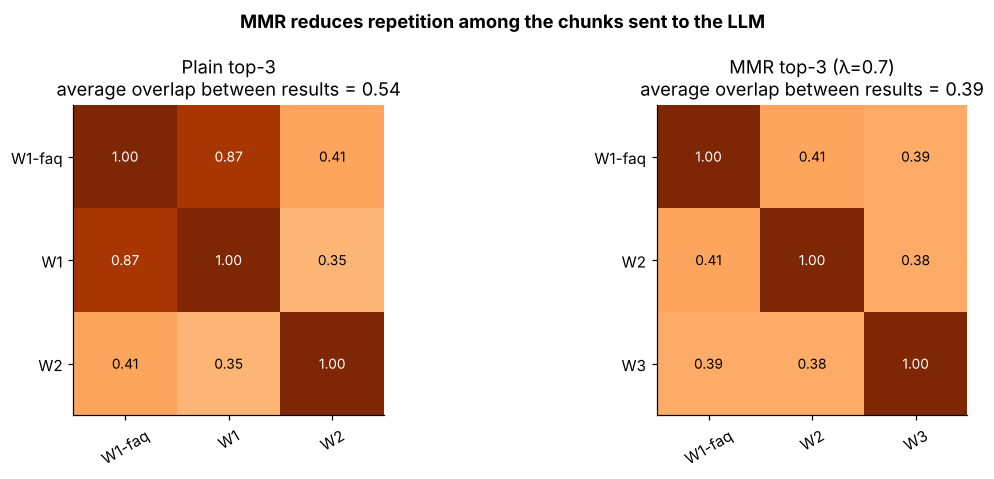

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (name, lst) in zip(axes, [("Plain top-3", plain), ("MMR top-3 (λ=0.7)", diverse)]):
    M = np.array([[EMB[a] @ EMB[b] for b in lst] for a in lst])
    im = ax.imshow(M, cmap="Oranges", vmin=0, vmax=1)
    n = len(lst)
    ax.set_xticks(range(n)); ax.set_xticklabels(lst, rotation=30); ax.set_yticks(range(n)); ax.set_yticklabels(lst)
    for i in range(n):
        for j in range(n): ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=9,
                                   color="white" if M[i, j] > 0.7 else "black")
    off = M[~np.eye(n, dtype=bool)].mean()
    ax.set_title(f"{name}\naverage overlap between results = {off:.2f}")
fig.suptitle("MMR reduces repetition among the chunks sent to the LLM", fontweight="bold")
plt.tight_layout(); plt.show()

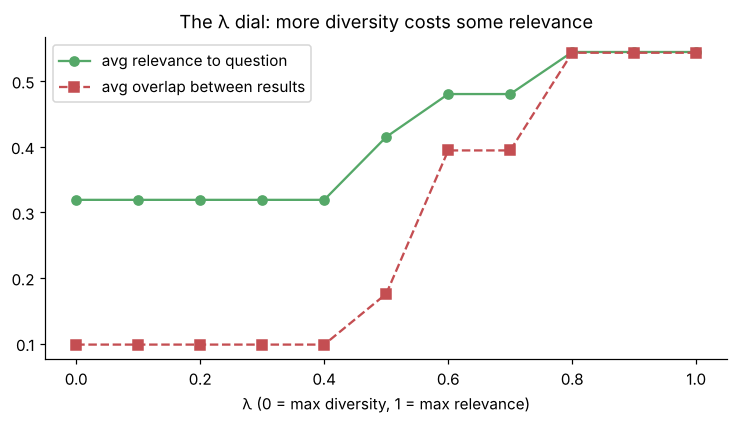

In [24]:
lams = np.linspace(0, 1, 11)
qv = model.encode([q], normalize_embeddings=True)[0]
relevance, redundancy = [], []
for l in lams:
    sel = mmr(q, cands, 3, l)
    relevance.append(np.mean([EMB[c] @ qv for c in sel]))
    redundancy.append(np.mean([EMB[a] @ EMB[b] for a in sel for b in sel if a != b]))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(lams, relevance, "o-", color=GREEN, label="avg relevance to question")
ax.plot(lams, redundancy, "s--", color=RED, label="avg overlap between results")
ax.set_xlabel("λ (0 = max diversity, 1 = max relevance)"); ax.legend()
ax.set_title("The λ dial: more diversity costs some relevance")
plt.show()

In **LangChain** you get this with `vectorstore.as_retriever(search_type="mmr", search_kwargs={"k": 4, "fetch_k": 20, "lambda_mult": 0.5})`.

## 10. Re-ranking with a cross-encoder
So far each chunk is embedded **separately** from the question (a *bi-encoder*). This is fast, because chunk vectors are computed once, but the model never reads the question and the chunk together.

A **cross-encoder** reads `[question + chunk]` as one input and outputs a relevance score. Much more accurate, but too slow to run on millions of chunks. So we use it as a second stage:

**retrieve 20 candidates fast (hybrid) → re-rank those 20 with the cross-encoder → keep the top 3–5.**

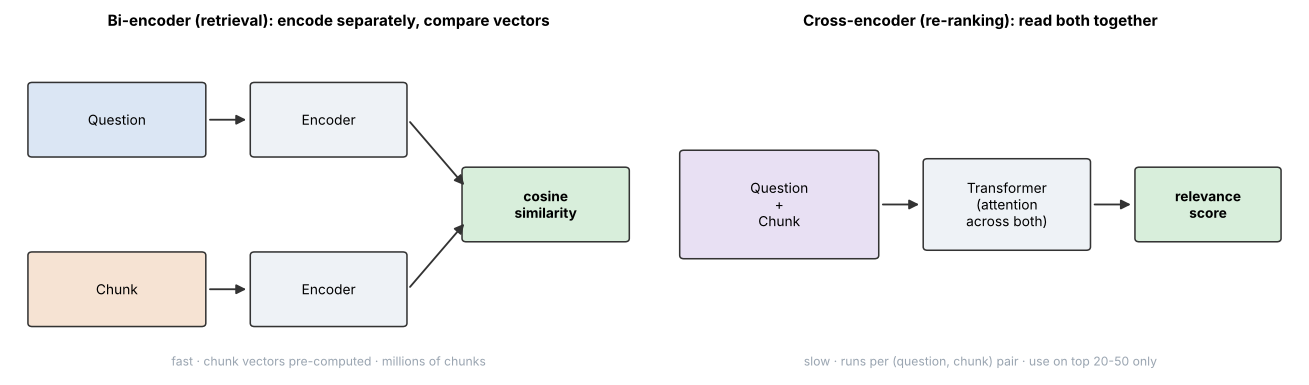

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax in axes: ax.set_xlim(0, 6); ax.set_ylim(0, 4); ax.axis("off")
a = axes[0]; a.set_title("Bi-encoder (retrieval): encode separately, compare vectors", fontsize=10, fontweight="bold")
box(a, 0.2, 2.6, 1.6, 0.8, "Question", "#dbe6f4"); box(a, 0.2, 0.6, 1.6, 0.8, "Chunk", "#f6e3d3")
box(a, 2.3, 2.6, 1.4, 0.8, "Encoder", "#eef2f6"); box(a, 2.3, 0.6, 1.4, 0.8, "Encoder", "#eef2f6")
box(a, 4.3, 1.6, 1.5, 0.8, "cosine\nsimilarity", "#d8eedb", True)
arrow(a, (1.85, 3.0), (2.25, 3.0)); arrow(a, (1.85, 1.0), (2.25, 1.0)); arrow(a, (3.75, 3.0), (4.3, 2.2)); arrow(a, (3.75, 1.0), (4.3, 1.8))
a.text(3, 0.1, "fast · chunk vectors pre-computed · millions of chunks", ha="center", fontsize=8, color=GREY)
b = axes[1]; b.set_title("Cross-encoder (re-ranking): read both together", fontsize=10, fontweight="bold")
box(b, 0.2, 1.4, 1.8, 1.2, "Question\n+\nChunk", "#e8e0f3")
box(b, 2.5, 1.5, 1.5, 1.0, "Transformer\n(attention\nacross both)", "#eef2f6")
box(b, 4.5, 1.6, 1.3, 0.8, "relevance\nscore", "#d8eedb", True)
arrow(b, (2.05, 2.0), (2.45, 2.0)); arrow(b, (4.05, 2.0), (4.45, 2.0))
b.text(3, 0.1, "slow · runs per (question, chunk) pair · use on top 20-50 only", ha="center", fontsize=8, color=GREY)
plt.tight_layout(); plt.show()

In [26]:
from sentence_transformers import CrossEncoder
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")

def rerank(query, candidate_ids, top=5):
    scores = reranker.predict([(query, TEXT[c]) for c in candidate_ids])
    order = np.argsort(-scores)
    return [(candidate_ids[i], float(scores[i])) for i in order[:top]]

q = "When is my appraisal?"
before = dense_ids(q, 10, where={"year": 2025})
after = [c for c, _ in rerank(q, before, top=10)]
print("Before:", before[:4]); print("After :", after[:4])
for c, s in rerank(q, before, 3): print(f"  {s:6.2f}  {c:4s} {TEXT[c]}")
# Dense put the expense rule (R1) first; the cross-encoder reads question + chunk together and promotes P1

Before: ['R1', 'P1', 'W1-chat', 'B2']
After : ['P1', 'R1', 'B3', 'W1-chat']
   -8.81  P1   Performance reviews take place twice a year, in June and December.
   -8.96  R1   Expense claims must be submitted within 30 days along with original receipts.
  -11.25  B3   The company gym on the 3rd floor is free for employees and open from 6 am to 10 pm.


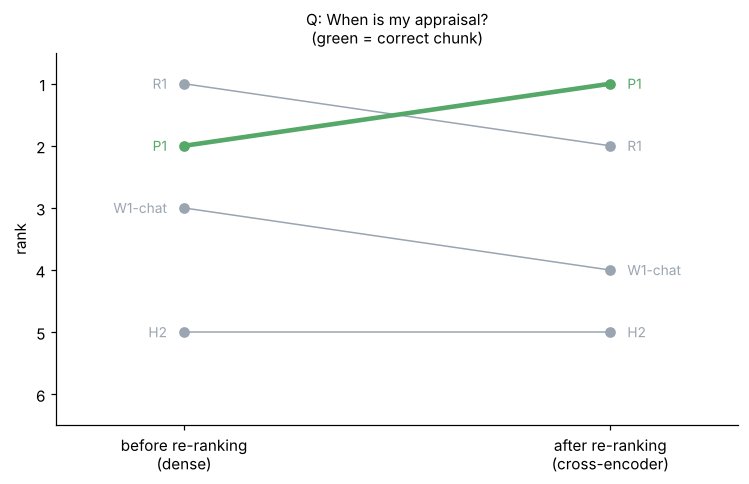

In [27]:
def slope_chart(q, before, after, correct, top=6):
    fig, ax = plt.subplots(figsize=(8, 4.4))
    for cid in set(before[:top]) | set(after[:top]):
        rb = before.index(cid) + 1 if cid in before else None
        ra = after.index(cid) + 1 if cid in after else None
        if rb and ra and max(rb, ra) <= top:
            c = GREEN if cid in correct else GREY
            ax.plot([0, 1], [rb, ra], "o-", color=c, lw=3 if cid in correct else 1)
            ax.text(-0.04, rb, cid, ha="right", va="center", fontsize=9, color=c)
            ax.text(1.04, ra, cid, ha="left", va="center", fontsize=9, color=c)
    ax.set_xlim(-0.3, 1.3); ax.set_ylim(top + 0.5, 0.5); ax.set_xticks([0, 1])
    ax.set_xticklabels(["before re-ranking\n(dense)", "after re-ranking\n(cross-encoder)"])
    ax.set_ylabel("rank"); ax.set_title(f"Q: {q}\n(green = correct chunk)", fontsize=10)
    plt.show()
slope_chart(q, before, after, {"P1"})

In [28]:
def hybrid_rerank_ids(q, k=10):
    cands = hybrid_ids(q, 20, year=2025)
    return [c for c, _ in rerank(q, cands, top=k)]
results["Hybrid + filter"] = evaluate(lambda q: hybrid_ids(q, 10, year=2025))
results["Hybrid + filter + re-rank"] = evaluate(hybrid_rerank_ids)
pd.DataFrame(results).T

,Hit@1,Hit@3,Hit@5,Recall@1,Recall@3,Recall@5,MRR
Dense,0.85,1.0,1.0,0.81,0.98,1.00,0.908
Dense + year filter,0.85,1.0,1.0,0.81,0.98,1.00,0.925
Hybrid + filter,0.80,1.0,1.0,0.76,0.98,1.00,0.892
Hybrid + filter + re-rank,0.95,1.0,1.0,0.91,0.98,0.99,0.975


## 11. Query transformation: fixing the question itself
Users write short, vague or oddly worded questions. Three popular fixes (in real apps, an LLM does the rewriting; here we write the rewrites by hand so the notebook runs without an API key):

| Technique | Idea | Example |
|---|---|---|
| **Query rewriting** | Turn the user's words into document words | "When is my appraisal?" → "performance review schedule" |
| **Multi-query** | Ask several versions, merge results with RRF | "time off" → annual leave / sick leave / carry forward |
| **HyDE** (Hypothetical Document Embeddings) | Let the LLM write a *fake answer*, then search with the answer's embedding | Answers look more like chunks than questions do |

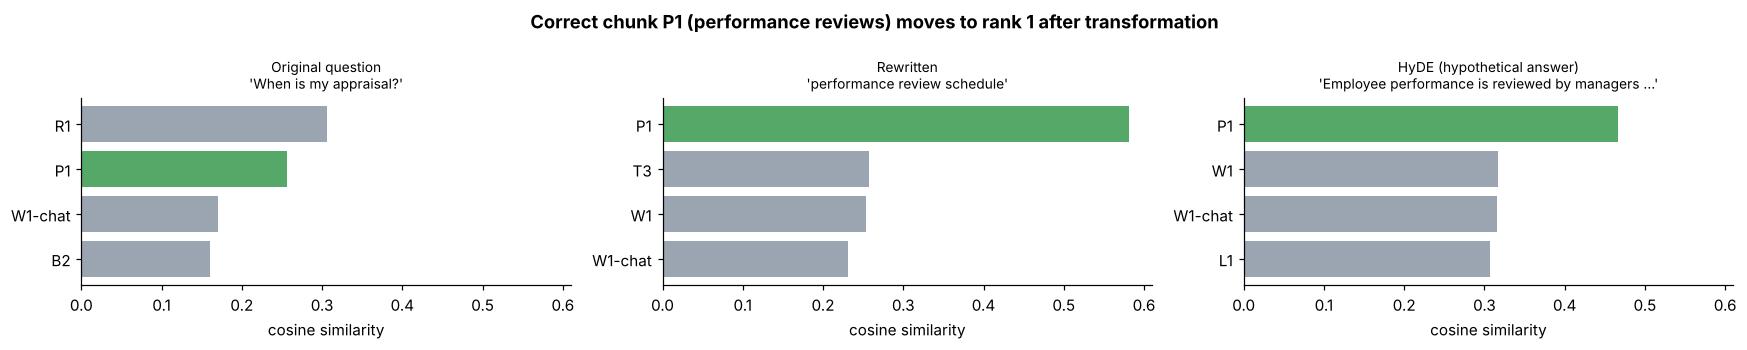

In [29]:
q = "When is my appraisal?"
variants = {
    "Original question": q,
    "Rewritten": "performance review schedule",
    "HyDE (hypothetical answer)": "Employee performance is reviewed by managers in scheduled appraisal cycles during the year.",
}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.2), sharex=True)
for ax, (name, text) in zip(axes, variants.items()):
    res = dense_search(text, 4, where={"year": 2025})
    labels = [c for c, _ in res][::-1]; scores = [s for _, s in res][::-1]
    ax.barh(labels, scores, color=[GREEN if c == "P1" else GREY for c in labels])
    ax.set_title(f"{name}\n'{text[:45]}…'" if len(text) > 45 else f"{name}\n'{text}'", fontsize=9)
    ax.set_xlabel("cosine similarity")
fig.suptitle("Correct chunk P1 (performance reviews) moves to rank 1 after transformation", fontweight="bold")
plt.tight_layout(); plt.show()

Single query : ['W1-chat', 'W1-faq', 'B3', 'W1'] → covers 0 of 4 leave rules
Multi-query  : ['L2', 'L1', 'L3', 'W1-chat'] → covers 3 of 4 leave rules


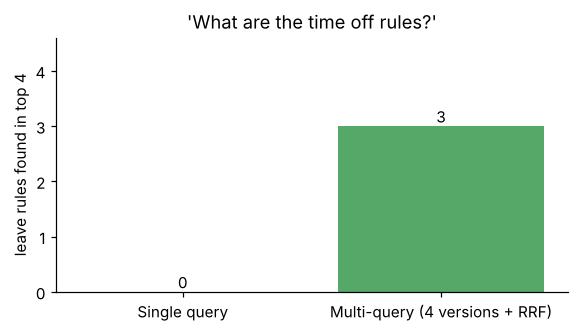

In [30]:
vague = "What are the time off rules?"
sub_queries = ["How many annual leave days do employees get?",
               "How many sick leave days are there?",
               "Can unused leave be carried forward?",
               "How long is maternity and paternity leave?"]
leave_chunks = {"L1", "L2", "L3", "L4"}

single = dense_ids(vague, 4, where={"year": 2025})
multi = rrf(*[dense_ids(s, 4, where={"year": 2025}) for s in sub_queries])[:4]
print("Single query :", single, "→ covers", len(set(single) & leave_chunks), "of 4 leave rules")
print("Multi-query  :", multi, "→ covers", len(set(multi) & leave_chunks), "of 4 leave rules")

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(["Single query", "Multi-query (4 versions + RRF)"],
              [len(set(single) & leave_chunks), len(set(multi) & leave_chunks)], color=[GREY, GREEN])
ax.bar_label(bars); ax.set_ylim(0, 4.6); ax.set_ylabel("leave rules found in top 4")
ax.set_title(f"'{vague}'"); plt.show()

With an LLM, generating the sub-queries looks like this (any provider works the same way):
```python
prompt = f"""Write 4 different search queries that would help answer this question.
Return one per line, no numbering.
Question: {user_question}"""
sub_queries = llm(prompt).strip().split("\n")
```
LangChain has this built in as `MultiQueryRetriever`.

## 12. Putting it all together
A complete retriever, then the prompt we send to the LLM. Every chunk carries an **ID** so the LLM can **cite its source**, and students (or users) can check the answer.

In [31]:
def retrieve(question, k=3, year=2025, threshold=THRESHOLD, use_rerank=True):
    cands = hybrid_ids(question, 20, year=year)                 # 1. hybrid + filter
    if use_rerank:
        ranked = [c for c, _ in rerank(question, cands, top=10)]          # 2. cross-encoder
    else:
        ranked = cands
    best = dense_search(question, 1, where={"year": year})[0][1]
    if best < threshold:                                                  # 3. "I don't know" guard
        return []
    return mmr(question, ranked[:8], k=k, lam=0.7)                        # 4. remove duplicates

def build_prompt(question, chunk_ids):
    if not chunk_ids:
        return None
    context = "\n".join(f"[{c}] {TEXT[c]}" for c in chunk_ids)
    return f"""You are Nova Retail's HR assistant. Answer ONLY from the context below.
Cite the chunk IDs you used in square brackets. If the context does not contain the answer, say
"I couldn't find this in the handbook."

Context:
{context}

Question: {question}
Answer:"""

for q in ["Can I fly business class to London?", "Can I bring my dog to the office?"]:
    ids = retrieve(q)
    print("=" * 90); print("Q:", q, "→ retrieved", ids)
    print(build_prompt(q, ids) or "No relevant chunks → reply 'I couldn't find this in the handbook.' without calling the LLM")

Q: Can I fly business class to London? → retrieved ['T2', 'T4', 'T1']
You are Nova Retail's HR assistant. Answer ONLY from the context below.
Cite the chunk IDs you used in square brackets. If the context does not contain the answer, say
"I couldn't find this in the handbook."

Context:
[T2] Business class is allowed only for international flights longer than 6 hours, with director approval.
[T4] The daily meal allowance during business travel is Rs 1,500 in metro cities.
[T1] Economy class is used for all flights shorter than 6 hours.

Question: Can I fly business class to London?
Answer:
Q: Can I bring my dog to the office? → retrieved []
No relevant chunks → reply 'I couldn't find this in the handbook.' without calling the LLM


### Optional: send it to an LLM
Set an API key and uncomment. Any chat model works; this example uses the Anthropic SDK (`pip install anthropic`).
```python
import anthropic
client = anthropic.Anthropic()          # reads ANTHROPIC_API_KEY from the environment
q = "Can I fly business class to London?"
msg = client.messages.create(model="claude-sonnet-5-5", max_tokens=300,
                             messages=[{"role": "user", "content": build_prompt(q, retrieve(q))}])
print(msg.content[0].text)
```
Expected style of answer: *"Only if the international flight is longer than 6 hours and a director approves it [T2]."*

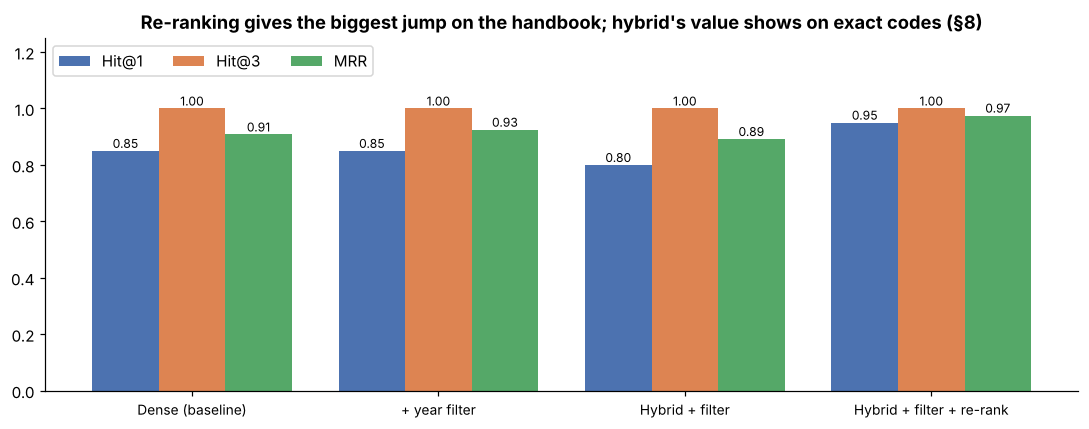

,Hit@1,Hit@3,Hit@5,Recall@1,Recall@3,Recall@5,MRR
Dense (baseline),0.85,1.0,1.0,0.81,0.98,1.00,0.908
+ year filter,0.85,1.0,1.0,0.81,0.98,1.00,0.925
Hybrid + filter,0.80,1.0,1.0,0.76,0.98,1.00,0.892
Hybrid + filter + re-rank,0.95,1.0,1.0,0.91,0.98,0.99,0.975


In [32]:
final = {"Dense (baseline)": baseline,
         "+ year filter": results["Dense + year filter"],
         "Hybrid + filter": results["Hybrid + filter"],
         "Hybrid + filter + re-rank": results["Hybrid + filter + re-rank"]}
table = pd.DataFrame(final).T
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(table)); w = 0.27
for j, (m, c) in enumerate([("Hit@1", BLUE), ("Hit@3", ORANGE), ("MRR", GREEN)]):
    bars = ax.bar(x + (j - 1) * w, table[m], w, label=m, color=c); ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(table.index, fontsize=9); ax.set_ylim(0, 1.25); ax.legend(loc="upper left", ncol=3)
ax.set_title("Re-ranking gives the biggest jump on the handbook; hybrid's value shows on exact codes (§8)", fontweight="bold")
plt.tight_layout(); plt.show()
table

## 13. Cheat sheet

| Problem | Symptom | Fix | Cost |
|---|---|---|---|
| Old / wrong documents retrieved | Answers quote outdated rules | **Metadata filter** (`where=`) | Free |
| Exact codes, IDs, acronyms missed | "VPN-415" returns VPN-417 | **BM25 + hybrid (RRF)** | Low |
| Right chunk found but ranked low | Hit@10 good, Hit@1 poor | **Cross-encoder re-ranking** | Medium (extra model) |
| Top results are near-duplicates | Same fact 3 times | **MMR** | Low |
| Vague or short questions | Low scores, scattered results | **Rewrite / multi-query / HyDE** | LLM call per query |
| Question not in documents | LLM invents an answer | **Similarity threshold** + "I don't know" prompt | Free |
| Don't know which fix helps | Guessing | **Golden test set + Hit@k / MRR** | Your time, worth it |

**LangChain equivalents**
```python
retriever = vectordb.as_retriever(search_kwargs={"k": 4, "filter": {"year": 2025}})        # top-k + filter
retriever = vectordb.as_retriever(search_type="mmr", search_kwargs={"k": 4, "fetch_k": 20})  # MMR
retriever = vectordb.as_retriever(search_type="similarity_score_threshold",
                                  search_kwargs={"score_threshold": 0.35})                   # threshold
from langchain.retrievers import EnsembleRetriever                                           # hybrid (RRF)
from langchain_community.retrievers import BM25Retriever
hybrid = EnsembleRetriever(retrievers=[BM25Retriever.from_documents(docs), retriever], weights=[0.4, 0.6])
```

## 14. Exercises
1. **Golden set:** write 5 new test questions (with correct chunk IDs) and re-run `evaluate()` for all methods. Does the ranking of methods change?
2. **Threshold:** add 10 more out-of-scope questions in §5. Find the threshold that wrongly blocks the fewest answerable questions.
3. **RRF weights:** on the error-code set, try `rrf(dense, bm25, weights=[0.3, 0.7])`. Plot MRR for weights from 0 to 1.
4. **MMR:** for "What are the rules for working remotely?", which λ gives the best Recall@3 against `["W1", "W2", "W3"]` (counting W1-faq and W1-chat as W1)?
5. **Your PDF:** load a PDF with your 3.1 code, store it in Chroma with page-number metadata, write 5 golden questions and report Hit@3 and MRR for dense vs hybrid + re-rank.
6. **Think:** re-ranking improved Hit@1, so why don't we run the cross-encoder on *every* chunk instead of only the top 20?